# Quantum Traffic Gridlock — Solution Notebook

**IBM Qiskit Fall Fest 2026 · QC@IITI**

This notebook walks through the full solution, from deriving the QUBO and running QAOA to checking the official scores, comparing baselines, and testing robustness.

Run the notebook from top to bottom to:

1. Create the two repository files: `traffic_qaoa.py` for the main library and `run.py` for the required command-line interface.
2. Verify the traffic model against the official `scorer.py` across all 256 possible schedules.
3. Build and inspect the QUBO for scenario **R**.
4. Run the required pipeline using `python run.py --scenario … --seed … --out …` for scenario R and, once available, scenario H.
5. Evaluate the required baselines, test robustness across five random seeds, compare different circuit depths, penalty weights, and initialisation methods, and assess generalisation using random scenarios drawn from the hidden-scenario ranges.

## Required Files

Keep `scorer.py` and `scenario_R.json` from the official ZIP file alongside the notebook (on Kaggle they are also found automatically under `/kaggle/input`). When scenario H is released, place it at `scenarios/scenario_H.json`. The notebook automatically processes every JSON file in the `scenarios/` directory.

## Requirements

* Python 3.10 or later
* `qiskit>=2.0`
* `numpy`, `scipy`, `matplotlib`, and `pandas` (used for displaying results only)

The notebook runs on a CPU and needs no network access once the packages are installed.


In [30]:
!pip install "qiskit>=2.0" numpy scipy matplotlib pandas   # Run this on a fresh machine or Colab if needed
import sys, json, subprocess, importlib, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import qiskit
print("python", sys.version.split()[0], "| qiskit", qiskit.__version__, "| numpy", np.__version__)

def find_input(name):
    """Find an official input file: working directory, scenarios/, then anywhere under /kaggle/input."""
    for root in (Path("."), Path("scenarios")):
        if (root / name).exists():
            return root / name
    kaggle = Path("/kaggle/input")
    hits = sorted(kaggle.rglob(name)) if kaggle.exists() else []
    if hits:
        return hits[0]
    raise FileNotFoundError(f"{name} not found. Put the official scorer.py and scenario_R.json next to the notebook.")

Path("scenarios").mkdir(exist_ok=True)
for fname in ["scenario_R.json"] + sorted(p.name for p in Path(".").glob("scenario_H*.json")):   # scenario H is picked up once released
    src_file = find_input(fname)
    if src_file.resolve() != (Path("scenarios") / fname).resolve():
        shutil.copy(src_file, Path("scenarios") / fname)
print(sorted(p.name for p in Path("scenarios").glob("*.json")))

python 3.13.15 | qiskit 2.5.2 | numpy 2.1.3
['scenario_H.json', 'scenario_R.json']


## 1. Library and CLI

This section writes the library and command-line interface to disk, so the project can run independently of the notebook.

`traffic_qaoa.py` brings together the traffic model, QUBO construction, NumPy statevector used during training, Qiskit circuit and sampler, evaluation metrics, baselines, and the separately labelled hybrid step.

The library is scenario-independent; it does not contain any hard-coded references to scenario R.

In [31]:
%%writefile traffic_qaoa.py
"""Quantum traffic gridlock: build the QUBO and run the QAOA pipeline.

The code is designed to work with different traffic scenarios.

Bit order throughout the file:
x = (A1, A2, A3, A4, B1, B2, B3, B4)
A value of 1 means NS is green; 0 means EW is green.

Schedule bit i maps to qubit (7 - i). This means a Qiskit counts key
(q7 ... q0) can be read directly as the schedule string
"A1A2A3A4B1B2B3B4".
"""
from __future__ import annotations

import itertools
import json
import math
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import numpy as np
from scipy.optimize import minimize

N_BITS = 8
NODES = ("A", "B")
PHASES = ("NS", "EW")
BIT_NAMES = [f"{n}{t + 1}" for n in NODES for t in range(4)]
ALL_X = np.array(list(itertools.product([0, 1], repeat=N_BITS)), dtype=int)  # Each row contains one schedule; MSB is A1


# ----------------------------------------------------------------------------------------
# 1. Traffic model: follows the official scorer and supplies values for the QUBO
# ----------------------------------------------------------------------------------------
def load_scenario(path):
    return json.loads(Path(path).read_text())


def transfer(fraction, departures):
    """Round fraction * departures to the nearest integer, with halves rounded up."""
    amt = Decimal(str(fraction)) * Decimal(int(departures))
    return int(amt.quantize(Decimal("1"), rounding=ROUND_HALF_UP))


def simulate(sc, bits):
    """Run the queue update for a schedule.

    Returns the queue after service and any overflow for each node, phase, and time:
    terms[(node, phase, t)] = (queue after service, overflow above storage).
    """
    plans = {"A": list(bits[:4]), "B": list(bits[4:])}
    cap, sto = sc["service_capacity"], sc["storage_capacity"]
    link = sc["link"]
    q = {(n, p): 0 for n in NODES for p in PHASES}
    pending = [0] * 4
    terms = {}
    for t in range(4):
        for n in NODES:
            for p in PHASES:
                inflow = sc["arrivals"][n][p][t] + (pending[t] if (n == "B" and p == link["phase"]) else 0)
                avail = q[(n, p)] + inflow
                green = plans[n][t] == (1 if p == "NS" else 0)
                dep = min(avail, cap) if green else 0
                q[(n, p)] = avail - dep
                terms[(n, p, t)] = (q[(n, p)], max(0, q[(n, p)] - sto))
                if n == "A" and p == link["phase"] and t < 3:
                    pending[t + 1] += transfer(link["fraction"], dep)
    return terms


def official_cost(sc, bits):
    terms = simulate(sc, bits)
    delay = sum(v[0] for v in terms.values())
    over = sum(v[1] for v in terms.values())
    sw = sum(bits[n * 4 + t] != bits[n * 4 + t - 1] for n in range(2) for t in range(1, 4))
    return float(delay + sc["overflow_weight"] * over + sc["switch_weight"] * sw)


def all_costs(sc):
    """Calculate the official cost for all 256 schedules.

    Index k corresponds to format(k, '08b'); this is used for benchmarking.
    """
    return np.array([official_cost(sc, list(x)) for x in ALL_X])


def term_support(sc, node, phase, t):
    """Find the schedule bits that can affect a queue term at time t."""
    own = [NODES.index(node) * 4 + s for s in range(t + 1)]
    if node == "B" and phase == sc["link"]["phase"]:
        own += [s for s in range(t)]  # Earlier A slots can feed B through the one-slot link delay
    return sorted(set(own))


# ----------------------------------------------------------------------------------------
# 2. Build the QUBO
# ----------------------------------------------------------------------------------------
def _walsh_quadratic(values, support):
    """Fit the degree-two Walsh expansion on a local set of schedule bits.

    values[j] corresponds to the local assignment bits of j, with the MSB
    matching support[0]. Returns the constant, linear terms, and pairwise
    terms in spin variables s = 1 - 2x, where s is the Z eigenvalue.
    """
    k = len(support)
    loc = np.array(list(itertools.product([0, 1], repeat=k)), dtype=int)
    s = 1 - 2 * loc
    const = values.mean()
    h, J = {}, {}
    for a in range(k):
        h[support[a]] = float((values * s[:, a]).mean())
        for b in range(a + 1, k):
            J[(support[a], support[b])] = float((values * s[:, a] * s[:, b]).mean())
    return float(const), h, J


def build_qubo(sc, method="walsh2", overflow_scale=1.0):
    """Build the Ising and QUBO forms of the traffic cost.

    The returned dictionary contains the Ising terms (const, h[8], and
    upper-triangular J) and the QUBO terms (offset and upper-triangular Q).

    With method="walsh2" (the default), each queue and overflow term is
    evaluated over the bits in its causal light-cone, then approximated
    using a degree-two Walsh expansion. Switching costs remain exact.

    With method="fluid", a linear fluid-queue approximation is used without
    the max(0, ...) clipping.
    """
    const, h, J = 0.0, np.zeros(N_BITS), np.zeros((N_BITS, N_BITS))
    wo, ws = sc["overflow_weight"] * overflow_scale, sc["switch_weight"]
    cap, sto, link = sc["service_capacity"], sc["storage_capacity"], sc["link"]
    if method == "walsh2":
        for n in NODES:
            for p in PHASES:
                for t in range(4):
                    sup = term_support(sc, n, p, t)
                    vals = []
                    for loc in itertools.product([0, 1], repeat=len(sup)):
                        bits = [0] * N_BITS
                        for i, b in zip(sup, loc):
                            bits[i] = b
                        qv, ov = simulate(sc, bits)[(n, p, t)]
                        vals.append(qv + wo * ov)
                    c0, hh, JJ = _walsh_quadratic(np.array(vals, float), sup)
                    const += c0
                    for i, v in hh.items():
                        h[i] += v
                    for (i, j), v in JJ.items():
                        J[i, j] += v
    elif method == "fluid":
        # Approximate the queue using cumulative arrivals and transfers minus service capacity.
        # For NS, green is x; for EW, green is 1-x. The result is converted to spin variables below.
        Qx = np.zeros((N_BITS, N_BITS)); lin = np.zeros(N_BITS); off = 0.0
        def add_sq(coef_vec, c, w):  # Add w * (coef.x + c)^2 to the quadratic expression
            nonlocal off
            for i in range(N_BITS):
                lin[i] += w * (coef_vec[i] ** 2 + 2 * c * coef_vec[i])
                for j in range(i + 1, N_BITS):
                    Qx[i, j] += w * 2 * coef_vec[i] * coef_vec[j]
            off += w * c * c
        for n in NODES:
            for p in PHASES:
                for t in range(4):
                    vec = np.zeros(N_BITS); c = float(sum(sc["arrivals"][n][p][:t + 1]))
                    for tau in range(t + 1):
                        i = NODES.index(n) * 4 + tau
                        if p == "NS":
                            vec[i] -= cap
                        else:
                            vec[i] += cap; c -= cap
                        if n == "B" and p == link["phase"] and tau >= 1:
                            j = tau - 1  # The earlier A slot that feeds this B slot
                            add = link["fraction"] * cap
                            if link["phase"] == "NS":
                                vec[j] += add
                            else:
                                vec[j] -= add; c += add
                    lin += vec; off += c                         # Add the approximate queue delay
                    add_sq(vec, c - sto, wo / (2.0 * max(sto, 1)))  # Approximate overflow with a quadratic penalty
        # Convert the polynomial in x to spin variables using x = (1 - s)/2
        for i in range(N_BITS):
            off += lin[i] / 2; h[i] += -lin[i] / 2
            for j in range(i + 1, N_BITS):
                q = Qx[i, j]
                off += q / 4; h[i] += -q / 4; h[j] += -q / 4; J[i, j] += q / 4
        const += off
    else:
        raise ValueError(method)
    # Switching cost is exact: ws * [x_t != x_{t+1}] = ws * (1 - s_t s_{t+1}) / 2
    for n in range(2):
        for t in range(3):
            i, j = n * 4 + t, n * 4 + t + 1
            const += ws / 2
            J[i, j] += -ws / 2
    return ising_to_qubo({"const": const, "h": h, "J": J, "method": method})


def ising_to_qubo(model):
    """Convert the Ising expression into its QUBO form.

    E(s) = const + sum h_i s_i + sum J_ij s_i s_j, with s_i = 1 - 2x_i.
    The result is E(x) = offset + sum_i Q_ii x_i + sum_{i<j} Q_ij x_i x_j.
    """
    const, h, J = model["const"], model["h"], model["J"]
    Q = np.zeros((N_BITS, N_BITS)); off = const
    for i in range(N_BITS):
        off += h[i]; Q[i, i] += -2 * h[i]
        for j in range(i + 1, N_BITS):
            off += J[i, j]; Q[i, i] += -2 * J[i, j]; Q[j, j] += -2 * J[i, j]; Q[i, j] += 4 * J[i, j]
    model.update({"Q": Q, "offset": off})
    return model


def qubo_energies(model):
    """Calculate the surrogate energy for all 256 schedules."""
    X = ALL_X
    Q = model["Q"]
    return model["offset"] + np.einsum("ki,ij,kj->k", X, np.triu(Q), X)


# ----------------------------------------------------------------------------------------
# 3. QAOA: train with an exact NumPy statevector and build the final Qiskit circuit
# ----------------------------------------------------------------------------------------
def qubit_of(i):
    return N_BITS - 1 - i


def basis_energy_vector(model, scale):
    """Return the normalised cost Hamiltonian diagonal in Qiskit's basis order.

    In basis index k, qubit q holds bit q of k. Since qubit 7-i stores
    schedule bit i, format(k, '08b') gives the schedule string.
    """
    return (qubo_energies(model) - model["const"]) / scale  # Drop the constant because it only adds a global phase


def ising_scale(model):
    """Scale the spectrum so its standard deviation over uniform schedules is 1."""
    return float(math.sqrt(np.sum(model["h"] ** 2) + np.sum(np.triu(model["J"], 1) ** 2))) or 1.0


def qaoa_state(Ediag, gammas, betas):
    psi = np.full(2 ** N_BITS, 1 / 16.0, dtype=complex)
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * Ediag)
        c, s = math.cos(b), -1j * math.sin(b)
        t = psi.reshape([2] * N_BITS)
        for ax in range(N_BITS):  # Apply exp(-i b X) to each qubit
            t0 = np.take(t, 0, axis=ax); t1 = np.take(t, 1, axis=ax)
            t = np.stack([c * t0 + s * t1, s * t0 + c * t1], axis=ax)
        psi = t.reshape(-1)
    return psi


class BudgetExceeded(Exception):
    pass


def optimise_qaoa(Ediag, p=4, seed=0, max_evals=300, init="tqa", scan=10):
    """Find the best gamma and beta values and return them with the evaluation history.

    Each statevector expectation calculation counts as one evaluation.
    """
    rng = np.random.default_rng(seed)
    hist = []
    best = {"f": np.inf, "x": None}

    def f(theta):
        if len(hist) >= max_evals:
            raise BudgetExceeded
        psi = qaoa_state(Ediag, theta[:p], theta[p:])
        val = float(np.real(np.vdot(psi, Ediag * psi)))
        hist.append(val)
        if val < best["f"]:
            best["f"], best["x"] = val, np.array(theta, float)
        return val

    def tqa(dt):
        k = (np.arange(p) + 0.5) / p
        # Use a Trotterised linear anneal from -sum X to H_C; this gives negative beta values.
        # exp(-i dt (1-s)(-X)) = exp(-i beta X), so beta = -(1-s) dt.
        return np.concatenate([k * dt, -(1 - k) * dt])

    try:
        if init == "tqa":
            grid = np.linspace(0.5, 1.25 * p + 0.5, scan)
            vals = [f(tqa(dt)) for dt in grid]
            x0 = tqa(grid[int(np.argmin(vals))])
            x0 = x0 + rng.normal(0, 0.02, size=x0.shape)  # Add a small seed-dependent variation
        else:  # Use random initial values for the ablation run
            x0 = np.concatenate([rng.uniform(0, math.pi, p), rng.uniform(-math.pi / 2, math.pi / 2, p)])
        remaining = max_evals - len(hist)
        minimize(f, x0, method="COBYLA", options={"maxiter": remaining, "rhobeg": 0.25})
        # If there is budget left, try a final refinement with Nelder-Mead
        remaining = max_evals - len(hist)
        if remaining > 2 * p + 5:
            minimize(f, best["x"], method="Nelder-Mead",
                     options={"maxfev": remaining, "xatol": 1e-4, "fatol": 1e-7, "initial_simplex": None})
    except BudgetExceeded:
        pass
    assert len(hist) <= max_evals
    th = best["x"]
    return th[:p], th[p:], hist

def build_circuit(model, scale, gammas, betas, measure=True):
    """Build the parameterised QAOA circuit.

    The cost layer applies exp(-i g H), where H contains the normalised
    h_i Z_i and J_ij Z_i Z_j terms.
    """
    from qiskit import QuantumCircuit
    h, J = model["h"] / scale, model["J"] / scale
    qc = QuantumCircuit(N_BITS)
    qc.h(range(N_BITS))
    for g, b in zip(gammas, betas):
        for i in range(N_BITS):
            for j in range(i + 1, N_BITS):
                if abs(J[i, j]) > 1e-12:
                    qi, qj = qubit_of(i), qubit_of(j)
                    qc.cx(qi, qj); qc.rz(float(2 * g * J[i, j]), qj); qc.cx(qi, qj)
        for i in range(N_BITS):
            if abs(h[i]) > 1e-12:
                qc.rz(float(2 * g * h[i]), qubit_of(i))
        for q in range(N_BITS):
            qc.rx(float(2 * b), q)
    if measure:
        qc.measure_all()
    return qc


def sample_circuit(qc, shots, seed):
    from qiskit.primitives import StatevectorSampler
    res = StatevectorSampler(default_shots=shots, seed=seed).run([qc]).result()
    return dict(sorted(res[0].data.meas.get_counts().items()))


def circuit_probabilities(qc):
    from qiskit.quantum_info import Statevector
    return Statevector(qc.remove_final_measurements(inplace=False)).probabilities()


# ----------------------------------------------------------------------------------------
# 4. Metrics, baselines, and the hybrid approach
# ----------------------------------------------------------------------------------------
def bits_of(key):
    return [int(c) for c in key]


def elite_set(costs, k=13):
    order = sorted(range(256), key=lambda i: (costs[i], format(i, "08b")))
    return set(order[:k])


def sampling_metrics(costs, counts):
    shots = sum(counts.values())
    EQ = sum(costs[int(k, 2)] * v for k, v in counts.items()) / shots
    Cstar, Crand = float(costs.min()), float(costs.mean())
    lift = (Crand - EQ) / (Crand - Cstar) if Crand > Cstar else float("nan")
    el = elite_set(costs)
    frac = sum(v for k, v in counts.items() if int(k, 2) in el) / shots
    return {"E_Q": EQ, "C_star": Cstar, "C_rand": Crand, "lift": lift,
            "elite_fraction": frac, "enrichment": frac / (13 / 256),
            "best_sampled_cost": min(costs[int(k, 2)] for k in counts)}


def baseline_alternating(sc):
    best = None
    for a in ("1010", "0101"):
        for b in ("1010", "0101"):
            c = official_cost(sc, bits_of(a + b))
            if best is None or c < best[1]:
                best = (a + b, c)
    return best


def available_at(sc, bits, t):
    """Get the vehicles present at each approach in slot t.

    Arrivals and transfers are included, while decisions from earlier slots
    are treated as fixed.
    """
    cap, link = sc["service_capacity"], sc["link"]
    q = {(n, p): 0 for n in NODES for p in PHASES}
    pending = [0] * 4
    for s in range(t + 1):
        avail = {}
        for n in NODES:
            for p in PHASES:
                avail[(n, p)] = q[(n, p)] + sc["arrivals"][n][p][s] + (pending[s] if (n == "B" and p == link["phase"]) else 0)
        if s == t:
            return avail
        for n_i, n in enumerate(NODES):
            for p in PHASES:
                green = bits[n_i * 4 + s] == (1 if p == "NS" else 0)
                dep = min(avail[(n, p)], cap) if green else 0
                q[(n, p)] = avail[(n, p)] - dep
                if n == "A" and p == link["phase"] and s < 3:
                    pending[s + 1] += transfer(link["fraction"], dep)


def baseline_greedy(sc):
    """Choose the phase with the larger queue in each slot; ties go to NS."""
    bits = [0] * 8
    for t in range(4):
        av = available_at(sc, bits, t)
        for n_i, n in enumerate(NODES):
            bits[n_i * 4 + t] = 1 if av[(n, "NS")] >= av[(n, "EW")] else 0
    return "".join(map(str, bits)), official_cost(sc, bits)


def hybrid_refine(sc, counts, top=16):
    """Run a separate local search starting from the most frequent QAOA samples.

    The top samples are refined using steepest descent with single-bit flips
    and the official cost function. This hybrid result is reported separately
    and is not part of the raw QAOA output.
    """
    cand = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))[:top]
    best = None; evals = 0
    for key, _ in cand:
        x = bits_of(key); c = official_cost(sc, x); evals += 1
        while True:
            nb = []
            for i in range(8):
                y = x.copy(); y[i] ^= 1; nb.append((official_cost(sc, y), y)); evals += 1
            cmin, ymin = min(nb, key=lambda t: t[0])
            if cmin < c - 1e-12:
                x, c = ymin, cmin
            else:
                break
        if best is None or c < best[1]:
            best = ("".join(map(str, x)), c)
    return {"schedule": best[0], "cost": best[1], "official_evaluations": evals}


# ----------------------------------------------------------------------------------------
# 5. Main pipeline, called by run.py
# ----------------------------------------------------------------------------------------
def run_pipeline(sc, seed=0, p=4, shots=4096, out=None, method="walsh2", max_evals=300,
                 init="tqa", overflow_scale=1.0, with_diagnostics=True):
    model = build_qubo(sc, method=method, overflow_scale=overflow_scale)
    scale = ising_scale(model)
    Ediag = basis_energy_vector(model, scale)
    gammas, betas, hist = optimise_qaoa(Ediag, p=p, seed=seed, max_evals=max_evals, init=init)
    qc = build_circuit(model, scale, gammas, betas)
    counts = sample_circuit(qc, shots, seed)
    assert sum(counts.values()) == shots
    # Check that the circuit and NumPy statevector give matching probabilities
    p_np = np.abs(qaoa_state(Ediag, gammas, betas)) ** 2
    p_qk = circuit_probabilities(qc)
    consistency = float(np.max(np.abs(p_np - p_qk)))

    E = qubo_energies(model)
    kq = int(np.argmin(E))
    most = max(counts.items(), key=lambda kv: (kv[1], -int(kv[0], 2)))[0]
    lowest_qubo_sample = min(counts, key=lambda k: (E[int(k, 2)], k))
    result = {"model": model, "scale": scale, "gammas": gammas, "betas": betas, "history": hist,
              "circuit": qc, "counts": counts, "consistency_max_abs_prob_diff": consistency,
              "qubo_argmin": format(kq, "08b"), "most_frequent": most,
              "lowest_qubo_sample": lowest_qubo_sample}
    if with_diagnostics:
        costs = all_costs(sc)  # Enumerate all schedules for benchmarking only
        result["costs"] = costs
        result["metrics"] = sampling_metrics(costs, counts)
        result["hybrid"] = hybrid_refine(sc, counts)
    if out is not None:
        write_outputs(sc, result, out, seed, p)
    return result


def write_outputs(sc, r, out, seed, p):
    from qiskit import qasm3
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    m = r["model"]
    bit_order = "A1 A2 A3 A4 B1 B2 B3 B4 (left to right); 1 = NS green, 0 = EW green"
    variables = [{"index": i, "name": BIT_NAMES[i], "qubit": qubit_of(i), "schedule_bit": i,
                  "auxiliary": False} for i in range(N_BITS)]
    qubo = {
        "scenario": sc.get("name"), "method": m["method"],
        "energy_convention": "E(x) = offset + sum_i Q[i][i] x_i + sum_{i<j} Q[i][j] x_i x_j, x_i in {0,1}",
        "Q": np.triu(m["Q"]).round(10).tolist(), "offset": round(float(m["offset"]), 10),
        "ising": {"convention": "E(s) = const + sum_i h_i s_i + sum_{i<j} J_ij s_i s_j, s_i = 1 - 2 x_i = <Z_qubit(i)>",
                  "h": m["h"].round(10).tolist(), "J": np.triu(m["J"], 1).round(10).tolist(),
                  "const": round(float(m["const"]), 10)},
        "circuit_normalisation": {"divide_h_J_by": r["scale"], "note": "constant dropped (global phase)"},
        "variables": variables, "auxiliary_variables": [], "num_qubits": N_BITS,
        "bit_order": bit_order,
        "qiskit_key_mapping": "counts key (q7..q0) == schedule string A1..B4",
    }
    (out / "qubo.json").write_text(json.dumps(qubo, indent=2))
    (out / "circuit.qasm").write_text(qasm3.dumps(r["circuit"]))
    (out / "counts.json").write_text(json.dumps(r["counts"], indent=1))
    sched = {
        "bit_order": bit_order,
        "raw_qaoa": {
            "most_frequent_sample": r["most_frequent"],
            "lowest_surrogate_energy_sample": r["lowest_qubo_sample"],
        },
        "qubo_exact_minimiser": r["qubo_argmin"],
        "seed": seed, "p": p, "training_evaluations": len(r["history"]),
        "gammas": [float(g) for g in r["gammas"]], "betas": [float(b) for b in r["betas"]],
        "consistency_max_abs_prob_diff": r["consistency_max_abs_prob_diff"],
    }
    sel = r["lowest_qubo_sample"]
    sched["selected_schedule"] = {"bits": sel, "A": bits_of(sel)[:4], "B": bits_of(sel)[4:],
                                  "source": "raw QAOA: among the 4096 sampled bitstrings, the one with the lowest "
                                            "surrogate (QUBO) energy - no official-scorer calls, no local search"}
    if "metrics" in r:
        costs = r["costs"]
        for key in ("most_frequent_sample", "lowest_surrogate_energy_sample"):
            b = sched["raw_qaoa"][key]
            sched["raw_qaoa"][key] = {"bits": b, "official_cost": float(costs[int(b, 2)])}
        sched["qubo_exact_minimiser"] = {"bits": r["qubo_argmin"],
                                         "official_cost": float(costs[int(r["qubo_argmin"], 2)])}
        sched["hybrid_HYBRID_NOT_RAW_QAOA"] = r["hybrid"]
        sched["diagnostics_benchmark_only"] = r["metrics"]
    (out / "schedule.json").write_text(json.dumps(sched, indent=2))


# ----------------------------------------------------------------------------------------
# 6. Random scenario generator, used only for generalisation experiments
# ----------------------------------------------------------------------------------------
def make_random_scenario(rng, name="rand"):
    """Generate a scenario using the hidden-scenario ranges from the problem statement."""
    return {"name": name,
            "arrivals": {n: {p: [int(v) for v in rng.integers(0, 9, 4)] for p in PHASES} for n in NODES},
            "service_capacity": int(rng.integers(4, 7)), "storage_capacity": int(rng.integers(5, 9)),
            "overflow_weight": float(rng.integers(2, 7)),
            "switch_weight": float(rng.choice([0.25, 0.5, 0.75, 1.0, 1.25, 1.5])),
            "link": {"from": "A", "to": "B", "phase": str(rng.choice(["NS", "EW"])),
                     "fraction": float(rng.choice([0.4, 0.5, 0.6, 0.7, 0.8]))}}

Overwriting traffic_qaoa.py


In [32]:
%%writefile run.py
"""Run the traffic QAOA pipeline for a given scenario.

Example: python run.py --scenario <scenario.json> --seed <int> --out <dir> [--p 4]

Builds the traffic QUBO, trains QAOA with at most 300 objective evaluations,
runs the circuit for exactly 4096 shots, and saves qubo.json, circuit.qasm,
counts.json, schedule.json, and metrics.json.
"""
import argparse
import json
import time
from pathlib import Path

import traffic_qaoa as T


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--scenario", required=True)
    ap.add_argument("--seed", type=int, required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--p", type=int, default=4, choices=[1, 2, 3, 4])
    ap.add_argument("--no-diagnostics", action="store_true",
                    help="skip benchmark enumeration (C*, lift) since it's not needed for the outputs")
    a = ap.parse_args()
    t0 = time.time()
    sc = T.load_scenario(a.scenario)
    r = T.run_pipeline(sc, seed=a.seed, p=a.p, shots=4096, out=a.out,
                       with_diagnostics=not a.no_diagnostics)
    summary = {"scenario": sc.get("name", Path(a.scenario).stem), "seed": a.seed, "p": a.p,
               "qubits": T.N_BITS, "training_evaluations": len(r["history"]),
               "circuit_depth": r["circuit"].depth(), "ops": dict(r["circuit"].count_ops()),
               "runtime_s": round(time.time() - t0, 2),
               "most_frequent_sample": r["most_frequent"]}
    if "metrics" in r:
        summary.update(r["metrics"]); summary["hybrid_HYBRID_NOT_RAW_QAOA"] = r["hybrid"]
    Path(a.out, "metrics.json").write_text(json.dumps(summary, indent=2, default=float))
    print(json.dumps(summary, indent=2, default=float))


if __name__ == "__main__":
    main()

Overwriting run.py


In [33]:
import traffic_qaoa as T
importlib.reload(T)

# Load the official scorer to check our implementation against it
spec = importlib.util.spec_from_file_location("scorer", find_input("scorer.py"))
scorer = importlib.util.module_from_spec(spec); spec.loader.exec_module(scorer)

R = T.load_scenario("scenarios/scenario_R.json")
checks = {"10101010": 116.0, "11111111": 146.0, "00000000": 237.0, "01111001": 92.5}
for b, ref in checks.items():
    print(b, "ours", T.official_cost(R, T.bits_of(b)), "| scorer.py", scorer.evaluate(R, b)["cost"], "| PS", ref)
    assert T.official_cost(R, T.bits_of(b)) == scorer.evaluate(R, b)["cost"] == ref

# Check all 256 schedules against the scorer on R and 200 randomly generated scenarios
rng = np.random.default_rng(2026)
for sc in [R] + [T.make_random_scenario(rng, f"chk{i}") for i in range(200)]:
    for k in range(256):
        b = format(k, "08b")
        assert abs(T.official_cost(sc, T.bits_of(b)) - scorer.evaluate(sc, b)["cost"]) < 1e-9
print("traffic model == official scorer on 201 scenarios x 256 schedules")

10101010 ours 116.0 | scorer.py 116.0 | PS 116.0
11111111 ours 146.0 | scorer.py 146.0 | PS 146.0
00000000 ours 237.0 | scorer.py 237.0 | PS 237.0
01111001 ours 92.5 | scorer.py 92.5 | PS 92.5
traffic model == official scorer on 201 scenarios x 256 schedules


## 2. From the Traffic Model to the QUBO

**Decision variables.** We use eight binary variables, \(x_i\in\{0,1\}\), for the four signals at intersections A and B, ordered as A1, A2, A3, A4, B1, B2, B3, B4. A value of \(x=1\) means the north–south (NS) direction has a green light. For an approach \((n,\varphi)\), the green indicator is

$$
g_{n,\varphi,t}=
\begin{cases}
x_{n,t}, & \varphi=\mathrm{NS},\\
1-x_{n,t}, & \text{otherwise}.
\end{cases}
$$

**Queue dynamics.** Queue lengths follow the Lindley recursion, which accounts for incoming traffic and the service provided by a green light. Given capacity \(c\), storage limit \(S\), and inflow \(a_{n,\varphi,t}\), the queue evolves as

$$
q_{n,\varphi,t}=\max\bigl(0,\;q_{n,\varphi,t-1}+a_{n,\varphi,t}-c\,g_{n,\varphi,t}\bigr),
\qquad q_{\cdot,\cdot,0}=0.
$$

For the linked approach at intersection B, the inflow also includes vehicles transferred from A:

$$
a_{B,\ell,t}=a^{\text{ext}}_{B,\ell,t}+
\Bigl\lfloor f\cdot \min\bigl(c,\,q_{A,\ell,t-1}+a_{A,\ell,t-1}\bigr)\,g_{A,\ell,t-1}+\tfrac12\Bigr\rfloor.
$$

The official cost combines queue lengths, overflow penalties, and signal switching:

$$
\sum_{n,\varphi,t}\bigl[q_{n,\varphi,t}+w_o\max(0,q_{n,\varphi,t}-S)\bigr]
+w_s\sum_{n,t}[x_{n,t}\neq x_{n,t+1}].
$$

**The switching cost is already quadratic.** A change between consecutive signal settings can be written exactly as

$$
[x_t\neq x_{t+1}]
=x_t+x_{t+1}-2x_tx_{t+1}
=\tfrac12(1-s_ts_{t+1}),
$$

where the spin variables are defined by \(s=1-2x\).

**Queue and overflow costs are not quadratic.** The clipping operation \(\max(0,\cdot)\) introduces higher-order pseudo-Boolean terms. However, each queue term depends on only a small, causally connected subset of the decision variables:

* A approaches at slot \(t\) depend only on A1 through A\(t\).
* B's unlinked approach depends only on B1 through B\(t\).
* B's linked approach depends on B1 through B\(t\) and A1 through A\(t-1\), reflecting the one-slot transfer delay. This involves at most seven bits.

**A scenario-independent modelling rule.** For each term \(\tau\), we evaluate the queue recursion over its local dependency set \(L_\tau\), which contains at most \(2^7\) possible states. We then retain only the degree-0, degree-1, and degree-2 terms in its Walsh–Fourier expansion:

$$
\hat\tau(S)=
\mathbb E_{s\in\{\pm1\}^{L_\tau}}
\left[\tau(s)\prod_{i\in S}s_i\right],
\qquad
\tau^{(2)}(s)=
\sum_{|S|\le2}\hat\tau(S)\prod_{i\in S}s_i.
$$

We sum these quadratic approximations across all 16 queue terms and add the exact switching cost. This produces an Ising model,

$$
E(s)=c_0+\sum_i h_is_i+\sum_{i<j}J_{ij}s_is_j,
$$

which is then converted into a QUBO using \(s_i=1-2x_i\).

**Why use this approximation?** Truncating the Walsh–Fourier expansion at degree two gives the unique quadratic approximation that minimises mean-squared error across the full schedule space. It also maximises the Pearson correlation with the true traffic cost among quadratic approximations. This is useful because QAOA samples are ultimately evaluated using the true cost, including metrics such as lift and enrichment.

The approximation is built directly from the traffic recursion, term by term. It does not search for the optimal schedule or encode a specific schedule into the model. No auxiliary variables are required, so the problem uses just eight qubits.

For comparison, we also retain a linear-fluid surrogate that removes the queue clipping and models overflow using a squared excess term.


Ising h: [ 20.812  25.812  18.938   7.125  -0.312 -10.938  -8.438  -5.188]
non-zero J pairs: 24 of 28
corr(surrogate, official) = 0.9949
QUBO argmin 11101010 -> official 72.0   |   true optimum C* = 72.0 at 11101010
surrogate regret = 0.00%


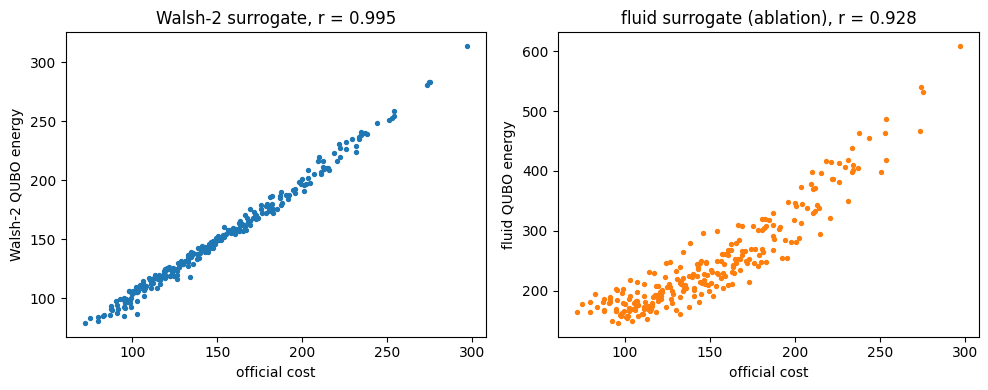

In [34]:
model = T.build_qubo(R)
E = T.qubo_energies(model)
C = T.all_costs(R)                      # Enumerate all schedules for benchmarking only
k = int(np.argmin(E))
print("Ising h:", np.round(model["h"], 3))
print("non-zero J pairs:", int((np.abs(np.triu(model["J"], 1)) > 1e-12).sum()), "of 28")
print(f"corr(surrogate, official) = {np.corrcoef(E, C)[0,1]:.4f}")
print(f"QUBO argmin {format(k,'08b')} -> official {C[k]}   |   true optimum C* = {C.min()} at {format(int(C.argmin()),'08b')}")
print(f"surrogate regret = {(C[k]-C.min())/C.min():.2%}")

fl = T.build_qubo(R, method="fluid"); Ef = T.qubo_energies(fl); kf = int(np.argmin(Ef))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(C, E, s=8); ax[0].set_xlabel("official cost"); ax[0].set_ylabel("Walsh-2 QUBO energy")
ax[0].set_title(f"Walsh-2 surrogate, r = {np.corrcoef(E, C)[0,1]:.3f}")
ax[1].scatter(C, Ef, s=8, color="tab:orange"); ax[1].set_xlabel("official cost"); ax[1].set_ylabel("fluid QUBO energy")
ax[1].set_title(f"fluid surrogate (ablation), r = {np.corrcoef(Ef, C)[0,1]:.3f}")
plt.tight_layout(); plt.show()

## 3. QAOA Design

* **Qubits:** The circuit uses 8 qubits, with schedule bit \(i\) mapped to qubit \(7-i\). This means a Qiskit counts key, \(q_7\dots q_0\), matches the schedule string A1…B4 directly. No auxiliary qubits are needed.

* **Cost layer:** Each layer applies \(e^{-i\gamma H}\), where

  $$
  H=\sum_i h_iZ_i+\sum_{i<j}J_{ij}Z_iZ_j.
  $$

  Before applying the cost Hamiltonian, its coefficients are scaled by

  $$
  \sqrt{\sum_i h_i^2+\sum_{i<j}J_{ij}^2}.
  $$

  This gives the Hamiltonian unit spectral standard deviation, helping the angles transfer across scenarios. The \(ZZ\) interactions are implemented with CX–RZ(\(2\gamma J\))–CX gates, while the single-qubit fields use RZ(\(2\gamma h\)). The constant offset is omitted because it contributes only a global phase.

* **Mixer:** Each qubit receives an RX(\(2\beta\)) rotation, starting from the uniform superposition \(|+\rangle^{\otimes 8}\). The circuit depth is set to \(p=4\), the maximum allowed depth; the ablation study compares other values.

* **Initialisation:** We initialise the parameters using a Trotterised quantum annealing schedule (TQA):

  $$
  \gamma_k=\frac{k-\tfrac12}{p}\Delta t,\qquad
  \beta_k=-\left(1-\frac{k-\tfrac12}{p}\right)\Delta t.
  $$

  The negative sign on \(\beta\) is intentional: with this mixer convention, it gives the appropriate annealing direction from the ground state of \(-\sum X\). We scan 10 values of \(\Delta t\) to choose the starting parameters.

* **Optimisation:** COBYLA is used first, followed by a Nelder–Mead polish, both minimising the exact expectation value \(\langle H\rangle\) calculated with the NumPy statevector. Each expectation calculation counts as one evaluation. A hard limit of **300 evaluations** is enforced, and the best parameters found are retained. The seed controls a small random perturbation of the initial parameters and the sampler.

* **Final run:** Once optimisation is complete, the circuit is built with Qiskit, exported to OpenQASM 3, and sampled using `StatevectorSampler` for exactly 4096 shots. The notebook then verifies that the probabilities from the Qiskit circuit match those of the trained NumPy statevector.


## 4. Required pipeline on every scenario in `scenarios/` (R now, H when released)

In [35]:
SEEDS = [0, 1, 2, 3, 4]
runs, SCEN = {}, {}
for path in sorted(Path("scenarios").glob("*.json")):
    name = T.load_scenario(path).get("name", path.stem)
    SCEN[name] = T.load_scenario(path)
    for seed in SEEDS:
        out = Path("outputs") / name / f"seed{seed}"
        cp = subprocess.run([sys.executable, "run.py", "--scenario", str(path), "--seed", str(seed), "--out", str(out)],
                            capture_output=True, text=True)
        assert cp.returncode == 0, cp.stderr
        runs[(name, seed)] = json.loads((out / "metrics.json").read_text())
    # Keep the seed 0 files as the main submission outputs
    for f in ["qubo.json", "circuit.qasm", "counts.json", "schedule.json", "metrics.json"]:
        shutil.copy(Path("outputs") / name / "seed0" / f, Path("outputs") / name / f)
print({k: round(v["lift"], 3) for k, v in runs.items()})
for name in SCEN:
    m = runs[(name, 0)]
    print(name, "(seed 0) | circuit depth", m["circuit_depth"], "| ops", m["ops"], "| runtime_s", m["runtime_s"])

{('H', 0): 0.851, ('H', 1): 0.872, ('H', 2): 0.835, ('H', 3): 0.871, ('H', 4): 0.857, ('R', 0): 0.774, ('R', 1): 0.777, ('R', 2): 0.776, ('R', 3): 0.782, ('R', 4): 0.779}
H (seed 0) | circuit depth 118 | ops {'cx': 192, 'rz': 128, 'rx': 32, 'h': 8, 'measure': 8, 'barrier': 1} | runtime_s 0.9
R (seed 0) | circuit depth 118 | ops {'cx': 192, 'rz': 128, 'rx': 32, 'h': 8, 'measure': 8, 'barrier': 1} | runtime_s 0.91


In [36]:
# Check that the saved files contain the expected results and pass basic validation
from qiskit import qasm3
for name in sorted({k[0] for k in runs}):
    d = Path("outputs") / name
    counts = json.loads((d / "counts.json").read_text())
    qubo = json.loads((d / "qubo.json").read_text())
    sched = json.loads((d / "schedule.json").read_text())
    assert sum(counts.values()) == 4096 and all(len(k) == 8 for k in counts)
    # Make sure the saved QUBO matches the Ising data and the in-memory model
    sc = SCEN[name]
    Q = np.array(qubo["Q"]); X = T.ALL_X
    E_file = qubo["offset"] + np.einsum("ki,ij,kj->k", X, Q, X)
    assert np.allclose(E_file, T.qubo_energies(T.build_qubo(sc)), atol=1e-6)
    txt = (d / "circuit.qasm").read_text()
    print(name, "| qasm lines", len(txt.splitlines()), "| distinct bitstrings", len(counts),
          "| selected", sched["selected_schedule"]["bits"], "| prob. consistency", sched["consistency_max_abs_prob_diff"])

H | qasm lines 373 | distinct bitstrings 105 | selected 10010110 | prob. consistency 4.163336342344337e-16
R | qasm lines 373 | distinct bitstrings 81 | selected 11101010 | prob. consistency 1.8041124150158794e-16


## 5. Baselines and diagnostics (R, and H when present)

In [37]:
import pandas as pd  # Used to display the results in a table
rows = []
for name in sorted({k[0] for k in runs}):
    sc = SCEN[name]
    C = T.all_costs(sc); m = runs[(name, 0)]
    E = T.qubo_energies(T.build_qubo(sc)); kq = int(np.argmin(E))
    alt = T.baseline_alternating(sc); gr = T.baseline_greedy(sc)
    rows += [
        (name, "(1) best of four alternating", alt[0], alt[1]),
        (name, "(2) greedy larger-queue (ties NS)", gr[0], gr[1]),
        (name, "(3) exact enumeration C*", format(int(C.argmin()), "08b"), C.min()),
        (name, "(4) uniform random E[C]", "-", C.mean()),
        (name, "(5) exact QUBO minimiser (surrogate ceiling)", format(kq, "08b"), C[kq]),
        (name, "(6a) raw QAOA mean cost E_Q (seed 0)", "-", m["E_Q"]),
        (name, "(6b) raw QAOA selected sample (lowest QUBO energy)", json.loads((Path('outputs')/name/'schedule.json').read_text())["selected_schedule"]["bits"],
         C[int(json.loads((Path('outputs')/name/'schedule.json').read_text())["selected_schedule"]["bits"], 2)]),
        (name, "(6c) HYBRID: QAOA top-16 + 1-flip local search", m["hybrid_HYBRID_NOT_RAW_QAOA"]["schedule"], m["hybrid_HYBRID_NOT_RAW_QAOA"]["cost"]),
    ]
pd.DataFrame(rows, columns=["scenario", "method", "schedule", "official cost"])

,scenario,method,schedule,official cost
0,H,(1) best of four alternating,10100101,261.000000
1,H,(2) greedy larger-queue (ties NS),10100111,244.000000
2,H,(3) exact enumeration C*,10000111,234.000000
3,H,(4) uniform random E[C],-,300.281250
4,H,(5) exact QUBO minimiser (surrogate ceiling),10010110,236.000000
5,H,(6a) raw QAOA mean cost E_Q (seed 0),-,243.851318
6,H,(6b) raw QAOA selected sample (lowest QUBO ene...,10010110,236.000000
7,H,(6c) HYBRID: QAOA top-16 + 1-flip local search,10000111,234.000000
8,R,(1) best of four alternating,10101010,116.000000
9,R,(2) greedy larger-queue (ties NS),01111001,92.500000


In [38]:
rows = []
for (name, seed), m in runs.items():
    rows.append((name, seed, m["E_Q"], m["C_star"], m["C_rand"], m["lift"], m["enrichment"], m["training_evaluations"]))
df = pd.DataFrame(rows, columns=["scenario", "seed", "E_Q", "C*", "C_rand", "lift", "enrichment", "evals"])
display(df.round(3))
print(df.groupby("scenario").agg(min_lift=("lift", "min"), mean_lift=("lift", "mean"),
                                 min_enrich=("enrichment", "min"), mean_enrich=("enrichment", "mean")).round(3))

,scenario,seed,E_Q,C*,C_rand,lift,enrichment,evals
0,H,0,243.851,234.0,300.281,0.851,16.034,300
1,H,1,242.500,234.0,300.281,0.872,16.803,300
2,H,2,244.943,234.0,300.281,0.835,15.298,300
3,H,3,242.521,234.0,300.281,0.871,16.659,300
4,H,4,243.451,234.0,300.281,0.857,16.216,300
5,R,0,89.889,72.0,151.250,0.774,11.447,300
6,R,1,89.683,72.0,151.250,0.777,11.495,300
7,R,2,89.766,72.0,151.250,0.776,11.457,300
8,R,3,89.268,72.0,151.250,0.782,11.995,300
9,R,4,89.550,72.0,151.250,0.779,11.716,300


          min_lift  mean_lift  min_enrich  mean_enrich
scenario                                              
H            0.835      0.857      15.298       16.202
R            0.774      0.778      11.447       11.622


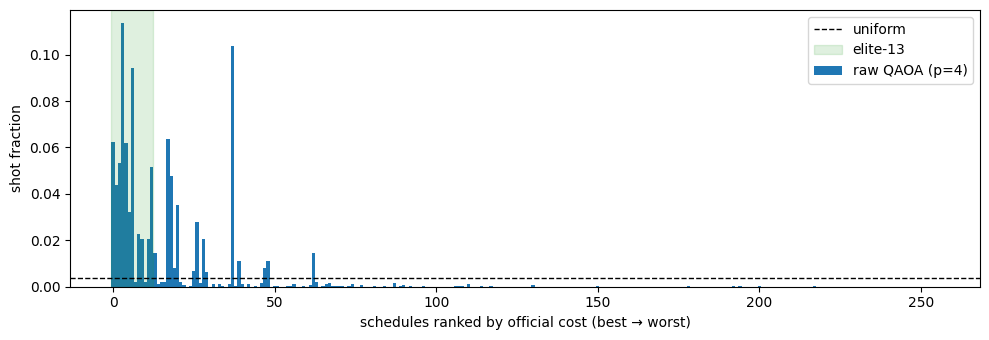

In [39]:
# Show how the 4096 raw QAOA shots are distributed by official cost (R, seed 0)
counts = json.loads(Path("outputs/R/counts.json").read_text())
C = T.all_costs(R); order = np.argsort(C, kind="stable")
p_qaoa = np.array([counts.get(format(i, "08b"), 0) for i in order]) / 4096
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(256), p_qaoa, width=1.0, label="raw QAOA (p=4)")
ax.axhline(1 / 256, color="k", ls="--", lw=1, label="uniform")
ax.axvspan(-0.5, 12.5, color="tab:green", alpha=0.15, label="elite-13")
ax.set_xlabel("schedules ranked by official cost (best → worst)"); ax.set_ylabel("shot fraction"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Ablations — depth, penalty weighting / surrogate, initialisation (scenario R, 5 seeds)

In [40]:
def lift_stats(sc, **kw):
    C = T.all_costs(sc); L, EN = [], []
    for s in SEEDS:
        r = T.run_pipeline(sc, seed=s, with_diagnostics=False, **kw)
        m = T.sampling_metrics(C, r["counts"]); L.append(m["lift"]); EN.append(m["enrichment"])
    return min(L), float(np.mean(L)), float(np.mean(EN))

abl = []
for p in [1, 2, 3, 4]:
    abl.append(("depth", f"p={p}", *lift_stats(R, p=p)))
for osc in [0.0, 0.5, 1.0, 2.0]:
    abl.append(("overflow weight in QUBO", f"x{osc}", *lift_stats(R, overflow_scale=osc)))
abl.append(("surrogate", "fluid (no clip)", *lift_stats(R, method="fluid")))
abl.append(("initialisation", "TQA (default)", *lift_stats(R)))
abl.append(("initialisation", "random", *lift_stats(R, init="random")))
pd.DataFrame(abl, columns=["ablation", "setting", "min lift", "mean lift", "mean enrichment"]).round(3)

,ablation,setting,min lift,mean lift,mean enrichment
0,depth,p=1,0.615,0.619,6.263
1,depth,p=2,0.729,0.733,10.143
2,depth,p=3,0.734,0.736,10.106
3,depth,p=4,0.774,0.778,11.622
4,overflow weight in QUBO,x0.0,0.708,0.714,8.376
5,overflow weight in QUBO,x0.5,0.766,0.773,11.306
6,overflow weight in QUBO,x1.0,0.774,0.778,11.622
7,overflow weight in QUBO,x2.0,0.776,0.780,11.906
8,surrogate,fluid (no clip),0.593,0.601,3.642
9,initialisation,TQA (default),0.774,0.778,11.622


In [41]:
# Compare surrogate regret across overflow penalty scales using 150 hidden-range scenarios
rng = np.random.default_rng(7)
pool = [T.make_random_scenario(rng, f"g{i}") for i in range(150)]
pool_C = [T.all_costs(s) for s in pool]
def regret(sc, C, **kw):
    E = T.qubo_energies(T.build_qubo(sc, **kw)); k = int(np.argmin(E)); return (C[k] - C.min()) / C.min()
rows = []
for label, kw in [("walsh2 x0.5", dict(overflow_scale=0.5)), ("walsh2 x1 (default)", {}),
                  ("walsh2 x2", dict(overflow_scale=2.0)), ("fluid", dict(method="fluid"))]:
    rg = np.array([regret(s, C, **kw) for s, C in zip(pool, pool_C)])
    rows.append((label, rg.mean(), np.median(rg), rg.max(), (rg <= 0.05).mean(), np.clip((0.25 - rg) / 0.20, 0, 1).mean()))
pd.DataFrame(rows, columns=["QUBO", "mean regret", "median", "max", "share <=5%", "rubric fraction"]).round(3)

,QUBO,mean regret,median,max,share <=5%,rubric fraction
0,walsh2 x0.5,0.017,0.003,0.148,0.860,0.976
1,walsh2 x1 (default),0.012,0.000,0.148,0.913,0.987
2,walsh2 x2,0.013,0.003,0.167,0.907,0.981
3,fluid,0.049,0.019,1.052,0.740,0.912


## 7. Generalisation study — 30 unseen random scenarios from the hidden ranges, 5 seeds each

Scenarios are drawn with arrivals 0–8, capacity 4–6, storage 5–8, overflow weight 2–6, switch weight 0.25–1.5, link phase NS/EW, fraction 0.4–0.8. The pipeline is the unmodified `run_pipeline`.

      regret  min lift  mean lift  min enrich  mean enrich
mean   0.008     0.793      0.801      11.574       11.929
min    0.000     0.651      0.691       4.591        4.724
50%    0.000     0.807      0.816      11.079       11.843
max    0.056     0.917      0.920      17.942       18.138


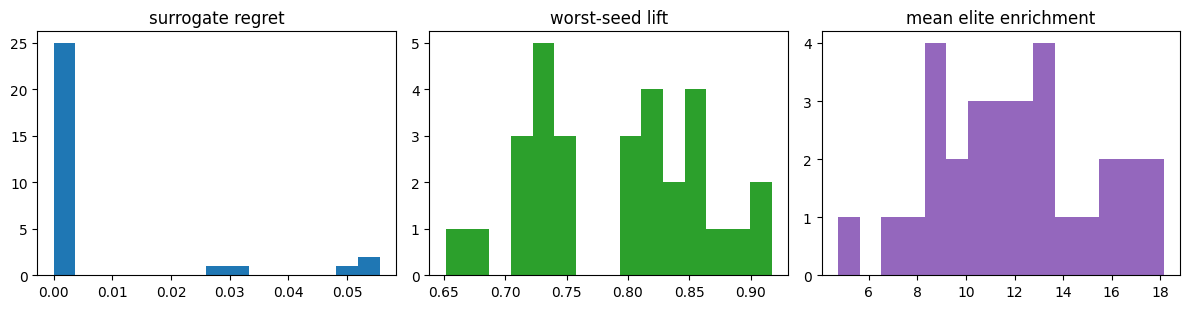

In [42]:
rng = np.random.default_rng(31415)
gen = []
for i in range(30):
    sc = T.make_random_scenario(rng, f"S{i}"); C = T.all_costs(sc)
    if C.mean() - C.min() < 5:   # organisers exclude near-degenerate scenarios
        continue
    E = T.qubo_energies(T.build_qubo(sc)); kq = int(np.argmin(E))
    L, EN = [], []
    for s in SEEDS:
        r = T.run_pipeline(sc, seed=s, with_diagnostics=False)
        m = T.sampling_metrics(C, r["counts"]); L.append(m["lift"]); EN.append(m["enrichment"])
    gen.append((sc["name"], (C[kq] - C.min()) / C.min(), min(L), np.mean(L), min(EN), np.mean(EN)))
g = pd.DataFrame(gen, columns=["scenario", "regret", "min lift", "mean lift", "min enrich", "mean enrich"])
print(g.describe().loc[["mean", "min", "50%", "max"]].round(3))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].hist(g["regret"], bins=15); ax[0].set_title("surrogate regret")
ax[1].hist(g["min lift"], bins=15, color="tab:green"); ax[1].set_title("worst-seed lift")
ax[2].hist(g["mean enrich"], bins=15, color="tab:purple"); ax[2].set_title("mean elite enrichment")
plt.tight_layout(); plt.show()

## 8. Resources, Limitations, and AI Use

* **Resources:** The implementation uses 8 qubits with a QAOA depth of \(p=4\), a hard limit of 300 objective evaluations, and exactly 4096 shots for the final sampling run. The per-seed runtime, circuit depth and gate counts are printed in Section 4. Training uses exact expectation values, without shot noise, while the final circuit is sampled using Qiskit's `StatevectorSampler`.

* **Surrogate limitations:** The degree-2 truncation leaves out higher-order interactions that arise from queue carry-over across three or more slots and from rounding in the link transfer. On the generalisation pool, regret is usually zero, but it reaches around 15% in a few scenarios where heavy overflow makes these higher-order effects more important. One possible extension is a degree-3 model with up to 8 additional auxiliary qubits, although the larger circuit could reduce the quality of raw sampling.

* **Enumeration for benchmarking only:** `all_costs` evaluates all 256 schedules to calculate \(C^*\), \(C_{\mathrm{rand}}\), lift, enrichment, and the baseline table. These evaluations are not used to build the QUBO or select the schedule. The selected schedule is the raw sample with the lowest surrogate energy; the local-search result is reported separately as **HYBRID**.

* **Quantum advantage:** No quantum advantage is claimed, since all 256 possible schedules can be enumerated almost instantly.

* **AI-use disclosure (the team's full statement is in the separate one-page disclosure):** AI assistance was used to interpret the problem statement, develop and refine the theoretical explanations, and draft the Markdown documentation in this notebook. The implementation strategy, formulas, and thresholds were reviewed against the simulation results in Sections 2–7. All reported numerical results are regenerated by running the notebook.